# Titanic Disaster: Exploratory Data Analysis (EDA)

**Core Objective:**
The goal of this exploratory data analysis is to uncover patterns and identify which demographic and socioeconomic factors increased a passenger's likelihood of survival.

### Key Questions to Investigate:
- What was the overall survival rate among passengers?
- Did passenger gender affect survival odds ("women and children first")?
- How did socioeconomic standing (ticket class, fare) influence rescue priority?
- What role did age and family composition play in survival outcomes?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/train.csv")

### 1. Initial Data Inspection & Health Check
In this section, we examine the structural dimensions, column data types, presence of duplicate records, and check for high-level data consistency.

In [3]:
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [4]:
print(f"(rows, columns) = {df.shape}")

(rows, columns) = (891, 12)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df["PassengerId"].is_unique

True

### 2. Missing Values Assessment
Quantifying missing values per column with absolute counts and percentages to determine appropriate imputation or drop strategies.

In [8]:
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100
missing_df = pd.DataFrame(
    {"Missing_Count": missing_count, "Percentage (%)": missing_pct.round(2)}
)
missing_df = (
    missing_df[missing_df["Missing_Count"] > 0]
    .sort_values(by="Missing_Count", ascending=False)
)
missing_df

,Missing_Count,Percentage (%)
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


### 3. Summary Statistics
Statistical breakdown of numerical variables (identifying distributions and potential outliers) alongside categorical distributions.

In [9]:
print(df.describe().T)

print(df.describe(exclude=["number"]).T)

             count        mean         std   min       25%       50%    75%  \
PassengerId  891.0  446.000000  257.353842  1.00  223.5000  446.0000  668.5   
Survived     891.0    0.383838    0.486592  0.00    0.0000    0.0000    1.0   
Pclass       891.0    2.308642    0.836071  1.00    2.0000    3.0000    3.0   
Age          714.0   29.699118   14.526497  0.42   20.1250   28.0000   38.0   
SibSp        891.0    0.523008    1.102743  0.00    0.0000    0.0000    1.0   
Parch        891.0    0.381594    0.806057  0.00    0.0000    0.0000    0.0   
Fare         891.0   32.204208   49.693429  0.00    7.9104   14.4542   31.0   

                  max  
PassengerId  891.0000  
Survived       1.0000  
Pclass         3.0000  
Age           80.0000  
SibSp          8.0000  
Parch          6.0000  
Fare         512.3292  
         count unique                      top freq
Name       891    891  Braund, Mr. Owen Harris    1
Sex        891      2                     male  577
Ticket     891    6

### 4. Data Cleaning & Missing Value Imputation
In this phase, we address data anomalies and missing values in `Embarked`, `Age`, and `Cabin`. We preserve raw data integrity by performing all cleaning procedures on an explicit copy of the dataset (`df_clean`).

In [10]:
df_clean = df.copy()

In [11]:
embarked_mode = df_clean["Embarked"].mode()[0]
embarked_mode

'S'

In [12]:
df_clean["Embarked"] = df_clean["Embarked"].fillna(embarked_mode)

In [13]:
df_clean['Embarked'].isnull().sum()

np.int64(0)

### Handling Missing Values: `Age`
Instead of using a simple global mean, missing age values are imputed using the median age grouped by passenger class (`Pclass`) and gender (`Sex`). This preserves realistic socio-demographic age distributions.

In [14]:
age_medians = df_clean.groupby(["Pclass", "Sex"])["Age"].transform("median")

In [15]:
df_clean["Age"] = df_clean["Age"].fillna(age_medians)

In [16]:
df_clean['Age'].isnull().sum()

np.int64(0)

### Handling Missing Values: `Cabin`
With over 77% missing values, direct categorical encoding of individual cabins is impractical. Instead, we engineer two informative features:
1. `Has_Cabin`: A binary flag (1 if a cabin was assigned, 0 otherwise).
2. `Deck`: The deck level extracted from the initial letter of the cabin identifier ('Unknown' for missing records).

In [17]:
df_clean["Has_Cabin"] = df_clean["Cabin"].notnull().astype(int)

In [18]:
df_clean["Deck"] = df_clean["Cabin"].str[0].fillna("Unknown")

In [19]:
df_clean["Deck"].value_counts()

Deck
Unknown    687
C           59
B           47
D           33
E           32
A           15
F           13
G            4
T            1
Name: count, dtype: int64

In [20]:
df_clean.groupby("Has_Cabin")["Survived"].mean().round(3)

Has_Cabin
0    0.300
1    0.667
Name: Survived, dtype: float64

In [21]:
df_clean.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
Has_Cabin        0
Deck             0
dtype: int64

### Dropping Raw Cabin Column
Since the actionable signals have been extracted into `Has_Cabin` and `Deck`, the original sparse `Cabin` column is dropped to maintain a tidy DataFrame.

In [22]:
df_clean = df_clean.drop(columns=["Cabin"])

In [23]:
len(df_clean.columns)

13

In [24]:
df_clean.columns.tolist()

['PassengerId',
 'Survived',
 'Pclass',
 'Name',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Ticket',
 'Fare',
 'Embarked',
 'Has_Cabin',
 'Deck']

### 5. Outlier & Anomaly Detection: `Fare`
We examine the distribution of fares, identify zero-fare passengers, and analyze extreme high-fare records using Interquartile Range (IQR) analysis to avoid improper data removal.

In [25]:
zero_fares = df_clean[df_clean["Fare"] == 0]
print(f"Total passengers with Fare = 0: {len(zero_fares)}")

Total passengers with Fare = 0: 15


In [26]:
zero_fares[["PassengerId", "Pclass", "Name", "Sex", "Age", "Ticket"]].head(5)

,PassengerId,Pclass,Name,Sex,Age,Ticket
179,180,3,"Leonard, Mr. Lionel",male,36.0,LINE
263,264,1,"Harrison, Mr. William",male,40.0,112059
271,272,3,"Tornquist, Mr. William Henry",male,25.0,LINE
277,278,2,"Parkes, Mr. Francis ""Frank""",male,30.0,239853
302,303,3,"Johnson, Mr. William Cahoone Jr",male,19.0,LINE


In [27]:
Q1 = df_clean["Fare"].quantile(0.25)
Q3 = df_clean["Fare"].quantile(0.75)
IQR = Q3 - Q1
upper_threshold = Q3 + (1.5 * IQR)

In [28]:
outliers_count = (df_clean["Fare"] > upper_threshold).sum()

In [29]:
print(f"Fare IQR: {IQR:.2f}")
print(f"Upper outlier threshold (Q3 + 1.5*IQR): {upper_threshold:.2f}")
print(f"Number of high-fare outliers: {outliers_count} ({outliers_count / len(df_clean) * 100:.2f}%)")

Fare IQR: 23.09
Upper outlier threshold (Q3 + 1.5*IQR): 65.63
Number of high-fare outliers: 116 (13.02%)


In [30]:
print("Top 5 Highest Fare Records:")
display(
    df_clean.sort_values(by="Fare", ascending=False)[
        ["PassengerId", "Name", "Pclass", "Fare", "Survived"]
    ].head(5)
)

Top 5 Highest Fare Records:


,PassengerId,Name,Pclass,Fare,Survived
679,680,"Cardeza, Mr. Thomas Drake Martinez",1,512.3292,1
258,259,"Ward, Miss. Anna",1,512.3292,1
737,738,"Lesurer, Mr. Gustave J",1,512.3292,1
88,89,"Fortune, Miss. Mabel Helen",1,263.0000,1
438,439,"Fortune, Mr. Mark",1,263.0000,0


### Outlier & Anomaly Detection: `Age`
Validating boundary values for age (infants and elderly passengers) to confirm historical plausibility.

In [31]:
min_age_passengers = df_clean[df_clean["Age"] < 1]
max_age_passengers = df_clean[df_clean["Age"] >= 70]

In [32]:
print(f"Infants under 1 year old: {len(min_age_passengers)}")
print(f"Elderly passengers aged 70 or above: {len(max_age_passengers)}")

Infants under 1 year old: 7
Elderly passengers aged 70 or above: 7


In [33]:
max_age_passengers[["PassengerId", "Name", "Age", "Pclass", "Survived"]]

,PassengerId,Name,Age,Pclass,Survived
96,97,"Goldschmidt, Mr. George B",71.0,1,0
116,117,"Connors, Mr. Patrick",70.5,3,0
493,494,"Artagaveytia, Mr. Ramon",71.0,1,0
630,631,"Barkworth, Mr. Algernon Henry Wilson",80.0,1,1
672,673,"Mitchell, Mr. Henry Michael",70.0,2,0
745,746,"Crosby, Capt. Edward Gifford",70.0,1,0
851,852,"Svensson, Mr. Johan",74.0,3,0


## 6. Exploratory Data Analysis (EDA) & Data Visualization

### 6.1. Overall Survival Rate
Investigating the baseline survival distribution to determine what proportion of passengers survived the disaster versus those who perished.

Survival Counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival Percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


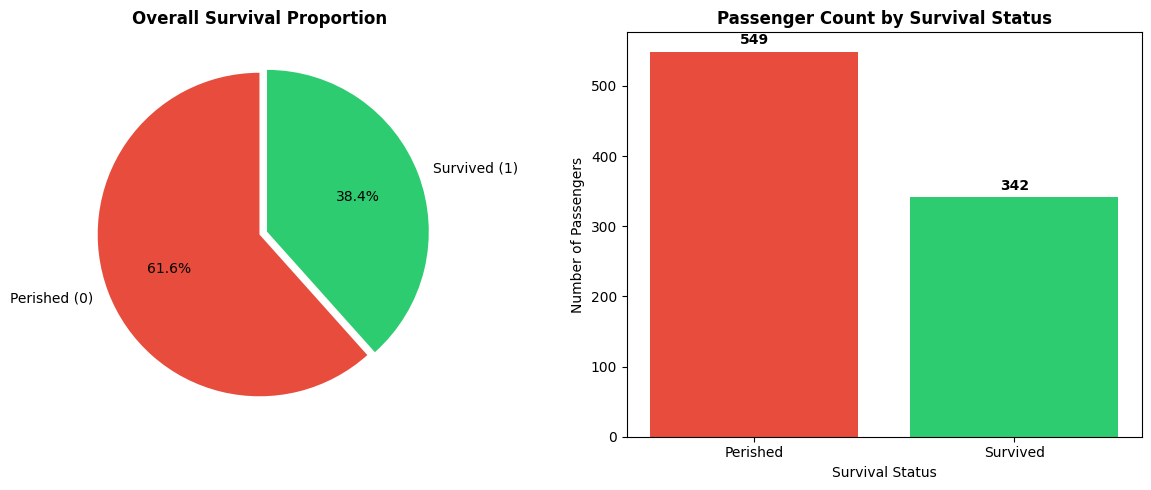

In [34]:
# 1. Calculate absolute frequencies and percentages
survived_counts = df_clean["Survived"].value_counts()
survived_pct = df_clean["Survived"].value_counts(normalize=True) * 100

print("Survival Counts:")
print(survived_counts)
print("\nSurvival Percentages:")
print(survived_pct.round(2))

# 2. Visualize using Matplotlib & Seaborn
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Pie Chart for Proportions
colors = ["#e74c3c", "#2ecc71"]  # Red for deceased (0), Green for survived (1)
axes[0].pie(
    survived_counts,
    labels=["Perished (0)", "Survived (1)"],
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    explode=[0, 0.05],
)
axes[0].set_title("Overall Survival Proportion", fontsize=12, fontweight="bold")

# Subplot 2: Native Bar Plot without version deprecation warnings
bars = axes[1].bar(
    ["Perished", "Survived"], survived_counts.values, color=colors
)
axes[1].set_title(
    "Passenger Count by Survival Status", fontsize=12, fontweight="bold"
)
axes[1].set_ylabel("Number of Passengers")
axes[1].set_xlabel("Survival Status")

# Modern, clean way to label bar heights directly
axes[1].bar_label(bars, padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

### 6.2. Survival by Gender: "Women and Children First"
Investigating the correlation between passenger gender and survival outcomes to assess the historical maritime protocol during evacuation.

Contingency Table (Sex vs Survived):


Survived,0,1,All
Sex,,,
female,81,233,314
male,468,109,577
All,549,342,891



Survival Rate by Gender (%):


Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

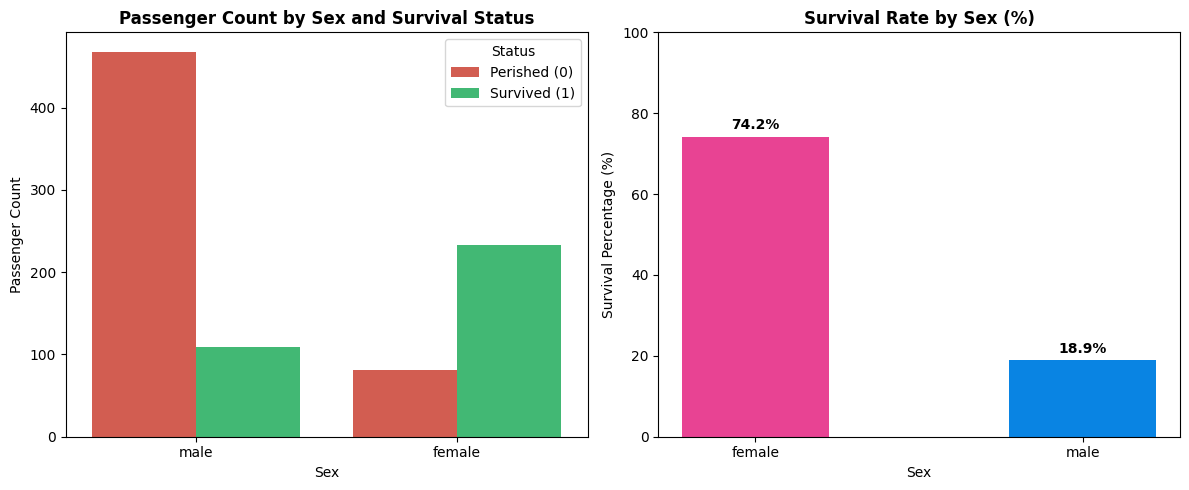

In [35]:
# 1. Statistical aggregation: Counts and Survival Rates by Gender
gender_cross = pd.crosstab(
    df_clean["Sex"], df_clean["Survived"], margins=True
)
gender_survival_rate = df_clean.groupby("Sex")["Survived"].mean() * 100

print("Contingency Table (Sex vs Survived):")
display(gender_cross)

print("\nSurvival Rate by Gender (%):")
display(gender_survival_rate.round(2))

# 2. Dual Visualization: Absolute Counts & Survival Rates
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Passenger Count by Gender and Survival Status
sns.countplot(
    data=df_clean,
    x="Sex",
    hue="Survived",
    palette=["#e74c3c", "#2ecc71"],
    ax=axes[0],
)
axes[0].set_title(
    "Passenger Count by Sex and Survival Status",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Passenger Count")
axes[0].legend(title="Status", labels=["Perished (0)", "Survived (1)"])

# Subplot 2: Survival Percentage per Gender
bars = axes[1].bar(
    gender_survival_rate.index,
    gender_survival_rate.values,
    color=["#e84393", "#0984e3"],
    width=0.45,
)
axes[1].set_title(
    "Survival Rate by Sex (%)", fontsize=12, fontweight="bold"
)
axes[1].set_ylabel("Survival Percentage (%)")
axes[1].set_xlabel("Sex")
axes[1].set_ylim(0, 100)
axes[1].bar_label(bars, fmt="%.1f%%", padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

### 6.3. Survival by Socioeconomic Status: Ticket Class (`Pclass`)
Analyzing how passenger class influenced survival outcomes to assess whether socioeconomic privilege correlated with evacuation priority.

Contingency Table (Pclass vs Survived):


Survived,0,1,All
Pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
All,549,342,891



Survival Rate by Ticket Class (%):


Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

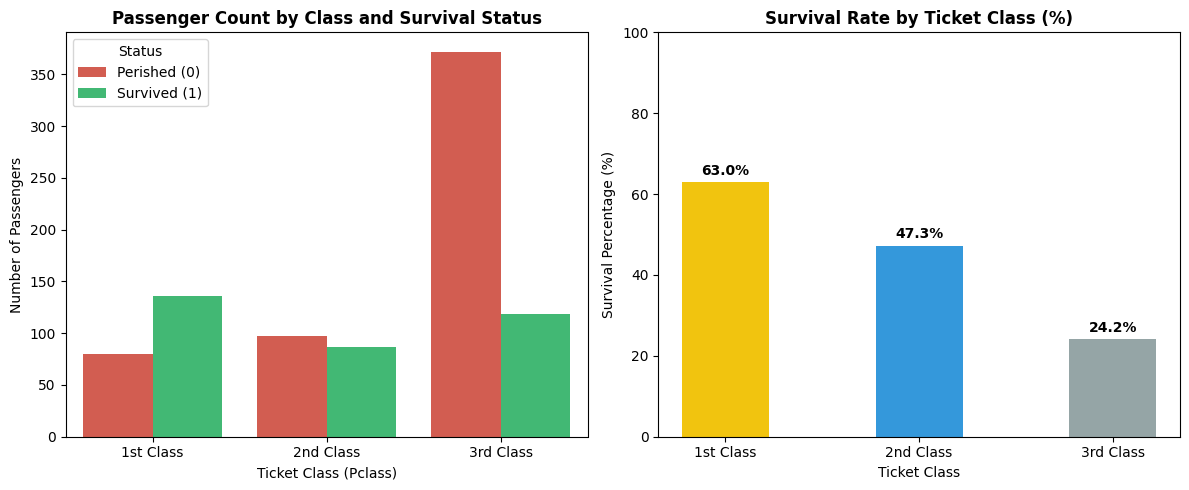

In [36]:
# 1. Statistical aggregation: Counts and Survival Rates by Ticket Class
pclass_crosstab = pd.crosstab(
    df_clean["Pclass"], df_clean["Survived"], margins=True
)
pclass_survival_rate = df_clean.groupby("Pclass")["Survived"].mean() * 100

print("Contingency Table (Pclass vs Survived):")
display(pclass_crosstab)

print("\nSurvival Rate by Ticket Class (%):")
display(pclass_survival_rate.round(2))

# 2. Dual Visualization: Passenger Count & Survival Percentage
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Subplot 1: Count of perished vs survived passengers per class
sns.countplot(
    data=df_clean,
    x="Pclass",
    hue="Survived",
    palette=["#e74c3c", "#2ecc71"],
    ax=axes[0],
)
axes[0].set_title(
    "Passenger Count by Class and Survival Status",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Ticket Class (Pclass)")
axes[0].set_ylabel("Number of Passengers")
# Set both tick positions and labels cleanly without warnings
axes[0].set_xticks([0, 1, 2], labels=["1st Class", "2nd Class", "3rd Class"])
axes[0].legend(title="Status", labels=["Perished (0)", "Survived (1)"])

# Subplot 2: Survival percentage per ticket class
class_labels = ["1st Class", "2nd Class", "3rd Class"]
class_colors = ["#f1c40f", "#3498db", "#95a5a6"]  # Gold, Blue, Gray

bars = axes[1].bar(
    class_labels, pclass_survival_rate.values, color=class_colors, width=0.45
)
axes[1].set_title(
    "Survival Rate by Ticket Class (%)", fontsize=12, fontweight="bold"
)
axes[1].set_ylabel("Survival Percentage (%)")
axes[1].set_xlabel("Ticket Class")
axes[1].set_ylim(0, 100)
axes[1].bar_label(bars, fmt="%.1f%%", padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

### 6.4. Age Distribution and Survival Outcomes
Analyzing age demographics across survival outcomes to evaluate whether evacuation priority favored children and to observe mortality rates among elderly passengers.

Age Groups Summary Table:


,Total_Passengers,Survived_Count,Survival_Rate
Age,,,
Child (0-12),69,40,57.97
Teen (13-18),70,30,42.86
Young Adult (19-35),514,184,35.80
Adult (36-60),216,83,38.43
Elderly (60+),22,5,22.73


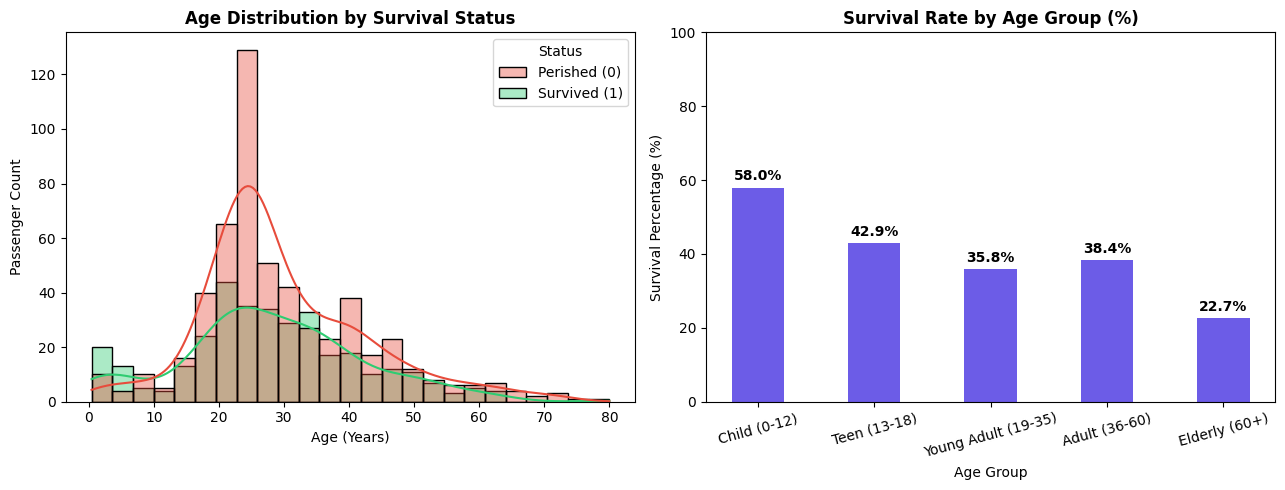

In [37]:
# 1. Statistical Breakdown: Binning Age into meaningful demographic categories
age_bins = [0, 12, 18, 35, 60, 100]
age_labels = [
    "Child (0-12)",
    "Teen (13-18)",
    "Young Adult (19-35)",
    "Adult (36-60)",
    "Elderly (60+)",
]

# Create temporary binned series for aggregation
temp_age_groups = pd.cut(df_clean["Age"], bins=age_bins, labels=age_labels)
age_summary = df_clean.groupby(temp_age_groups, observed=False)[
    "Survived"
].agg(
    Total_Passengers="count",
    Survived_Count="sum",
    Survival_Rate=lambda x: (x.mean() * 100).round(2),
)

print("Age Groups Summary Table:")
display(age_summary)

# 2. Dual Visualization: Continuous Distribution & Category Survival Rates
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Histogram + KDE Distribution
sns.histplot(
    data=df_clean,
    x="Age",
    hue="Survived",
    kde=True,
    bins=25,
    palette=["#e74c3c", "#2ecc71"],
    alpha=0.4,
    ax=axes[0],
)
axes[0].set_title(
    "Age Distribution by Survival Status", fontsize=12, fontweight="bold"
)
axes[0].set_xlabel("Age (Years)")
axes[0].set_ylabel("Passenger Count")

# Format legend labels cleanly without warnings
legend = axes[0].get_legend()
if legend:
    legend.set_title("Status")
    for text, label in zip(
        legend.get_texts(), ["Perished (0)", "Survived (1)"]
    ):
        text.set_text(label)

# Subplot 2: Survival Percentage per Demographic Age Group
survival_rates_by_age = age_summary["Survival_Rate"]
bars = axes[1].bar(
    range(len(survival_rates_by_age)),
    survival_rates_by_age.values,
    color="#6c5ce7",
    width=0.45,
)
axes[1].set_title(
    "Survival Rate by Age Group (%)", fontsize=12, fontweight="bold"
)
axes[1].set_ylabel("Survival Percentage (%)")
axes[1].set_xlabel("Age Group")
axes[1].set_ylim(0, 100)
axes[1].set_xticks(
    range(len(survival_rates_by_age)), labels=age_labels, rotation=15
)
axes[1].bar_label(bars, fmt="%.1f%%", padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

### 6.5. Fare Distribution and Survival Rate
Investigating the relationship between ticket fare and passenger survival. We compare median fares using boxplots and examine survival rates across fare quartiles to evaluate socioeconomic impact without outlier distortion.

--- Fare Summary Statistics by Survival Status ---


,Count,Mean,Median,Std,Min,Max
Survived,,,,,,
0,549,22.12,10.5,31.39,0.0,263.00
1,342,48.40,26.0,66.60,0.0,512.33



--- Survival Rate across Fare Quartiles ---


,Total_Passengers,Survived_Count,Survival_Rate
Fare,,,
Low (£0-£7.9),223,44,19.73
Mid-Low (£7.9-£14.5),224,68,30.36
Mid-High (£14.5-£31.0),222,101,45.50
High (£31.0+),222,129,58.11


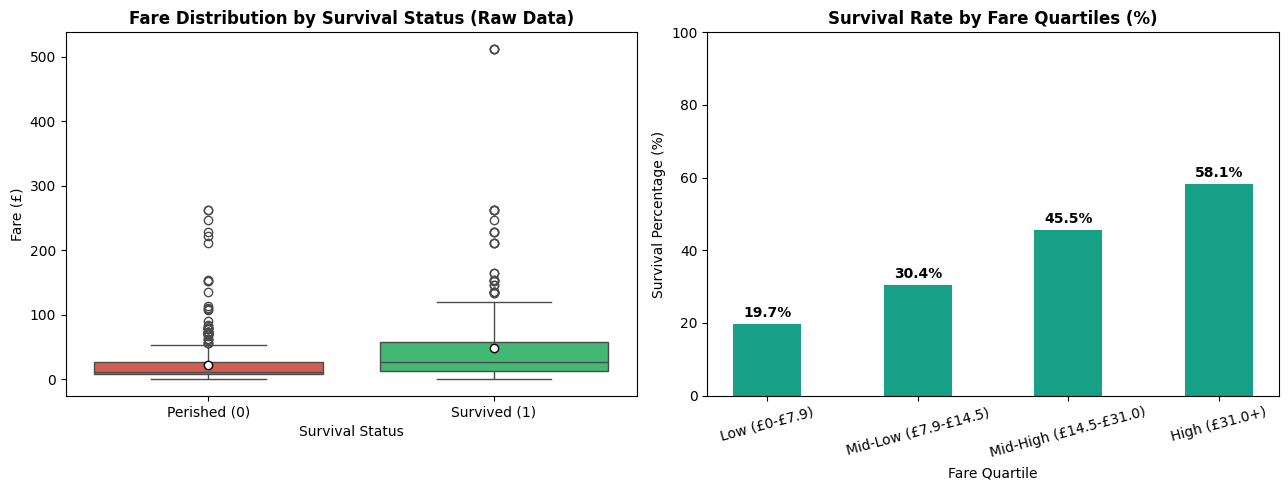

In [38]:
# 1. Statistical Breakdown: Summary metrics & Quartile binning
print("--- Fare Summary Statistics by Survival Status ---")
fare_stats = df_clean.groupby("Survived")["Fare"].agg(
    Count="count",
    Mean="mean",
    Median="median",
    Std="std",
    Min="min",
    Max="max",
)
display(fare_stats.round(2))

# Segment fare into 4 balanced quartiles
fare_labels = [
    "Low (£0-£7.9)",
    "Mid-Low (£7.9-£14.5)",
    "Mid-High (£14.5-£31.0)",
    "High (£31.0+)",
]
temp_fare_bins = pd.qcut(df_clean["Fare"], q=4, labels=fare_labels)

fare_quartile_summary = df_clean.groupby(temp_fare_bins, observed=False)[
    "Survived"
].agg(
    Total_Passengers="count",
    Survived_Count="sum",
    Survival_Rate=lambda x: (x.mean() * 100).round(2),
)

print("\n--- Survival Rate across Fare Quartiles ---")
display(fare_quartile_summary)

# 2. Dual Visualization: Boxplot & Quartile Survival Percentage
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Subplot 1: Boxplot of Raw Fare by Survival (with mean indicator)
sns.boxplot(
    data=df_clean,
    x="Survived",
    y="Fare",
    hue="Survived",
    palette=["#e74c3c", "#2ecc71"],
    ax=axes[0],
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "white",
        "markeredgecolor": "black",
    },
)
axes[0].set_title(
    "Fare Distribution by Survival Status (Raw Data)",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Survival Status")
axes[0].set_ylabel("Fare (£)")
axes[0].set_xticks([0, 1], labels=["Perished (0)", "Survived (1)"])

# Cleanly remove redundant legend created by hue
if axes[0].get_legend():
    axes[0].get_legend().remove()

# Subplot 2: Survival Rate across Fare Quartiles
quartile_rates = fare_quartile_summary["Survival_Rate"]
bars = axes[1].bar(
    range(len(quartile_rates)), quartile_rates.values, color="#16a085", width=0.45
)
axes[1].set_title(
    "Survival Rate by Fare Quartiles (%)", fontsize=12, fontweight="bold"
)
axes[1].set_ylabel("Survival Percentage (%)")
axes[1].set_xlabel("Fare Quartile")
axes[1].set_ylim(0, 100)
axes[1].set_xticks(
    range(len(quartile_rates)), labels=fare_labels, rotation=15
)
axes[1].bar_label(bars, fmt="%.1f%%", padding=3, fontweight="bold")

plt.tight_layout()
plt.show()

### 6.6. Multivariate Analysis: Class and Gender Interaction (`Pclass` & `Sex` vs `Survived`)
Investigating the compound effect of socioeconomic standing and gender on survival to determine whether gender priority superseded class privilege during evacuation.

--- Detailed Passenger Breakdown (Pclass x Sex) ---


Total_Passengers  Survived_Count  Survival_Rate
Pclass Sex                                                    
1      female                94              91          96.81
       male                 122              45          36.89
2      female                76              70          92.11
       male                 108              17          15.74
3      female               144              72          50.00
       male                 347              47          13.54


--- Survival Rate Pivot Table (%) ---


Sex,female,male
Pclass,,
1,96.81,36.89
2,92.11,15.74
3,50.00,13.54


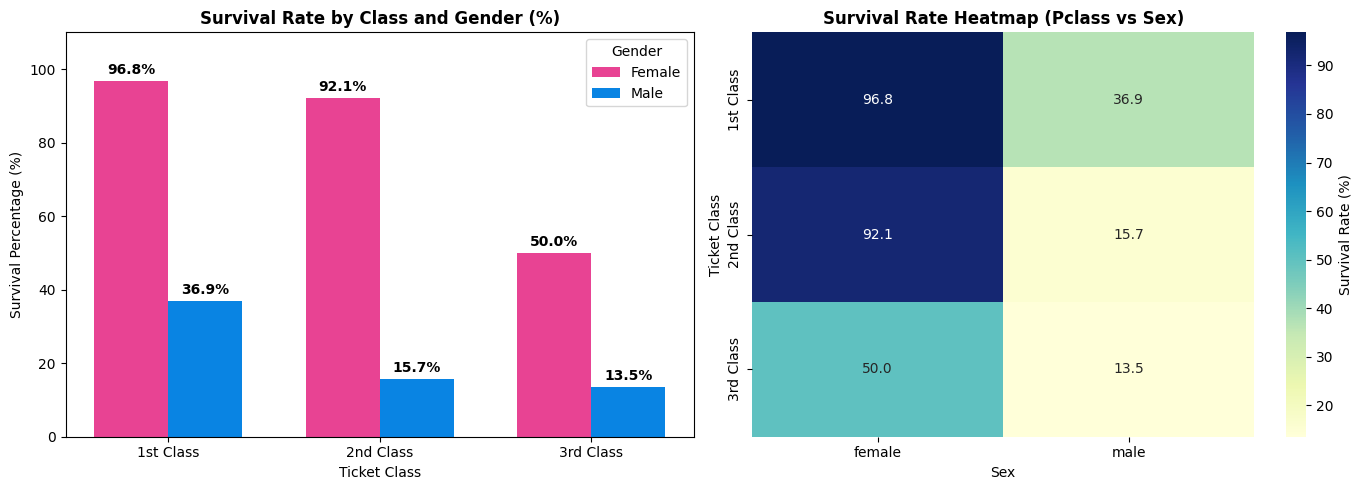

In [39]:
# 1. Pivot Table & Aggregation: Survival Rates across Pclass and Sex
pivot_survival = (
    df_clean.pivot_table(
        index="Pclass", columns="Sex", values="Survived", aggfunc="mean"
    )
    * 100
)

# Detailed breakdown table with total passenger counts
detailed_combo = df_clean.groupby(["Pclass", "Sex"])["Survived"].agg(
    Total_Passengers="count",
    Survived_Count="sum",
    Survival_Rate=lambda x: (x.mean() * 100).round(2),
)

print("--- Detailed Passenger Breakdown (Pclass x Sex) ---")
display(detailed_combo)

print("\n--- Survival Rate Pivot Table (%) ---")
display(pivot_survival.round(2))

# 2. Dual Visualization: Grouped Bar Chart & Survival Heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Clustered Bar Chart (Matplotlib Native - Zero Deprecation Warnings)
x_indices = np.arange(len(pivot_survival.index))
bar_width = 0.35

bars_female = axes[0].bar(
    x_indices - bar_width / 2,
    pivot_survival["female"],
    bar_width,
    label="Female",
    color="#e84393",
)
bars_male = axes[0].bar(
    x_indices + bar_width / 2,
    pivot_survival["male"],
    bar_width,
    label="Male",
    color="#0984e3",
)

axes[0].set_title(
    "Survival Rate by Class and Gender (%)", fontsize=12, fontweight="bold"
)
axes[0].set_ylabel("Survival Percentage (%)")
axes[0].set_xlabel("Ticket Class")
axes[0].set_ylim(0, 110)
axes[0].set_xticks(
    x_indices, labels=["1st Class", "2nd Class", "3rd Class"]
)
axes[0].legend(title="Gender")
axes[0].bar_label(bars_female, fmt="%.1f%%", padding=3, fontweight="bold")
axes[0].bar_label(bars_male, fmt="%.1f%%", padding=3, fontweight="bold")

# Subplot 2: Heatmap Matrix of Survival Rates
sns.heatmap(
    pivot_survival,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={"label": "Survival Rate (%)"},
    yticklabels=["1st Class", "2nd Class", "3rd Class"],
    ax=axes[1],
)
axes[1].set_title(
    "Survival Rate Heatmap (Pclass vs Sex)", fontsize=12, fontweight="bold"
)
axes[1].set_ylabel("Ticket Class")
axes[1].set_xlabel("Sex")

plt.tight_layout()
plt.show()

### 6.7. Feature Correlation Matrix
Evaluating linear relationships across all numerical attributes using Pearson's correlation coefficient to identify key survival drivers and potential multicollinearity.

--- Correlation Matrix ---


,Survived,Pclass,Age,SibSp,Parch,Fare,Has_Cabin
Survived,1.000,-0.338,-0.060,-0.035,0.082,0.257,0.317
Pclass,-0.338,1.000,-0.414,0.083,0.018,-0.549,-0.726
Age,-0.060,-0.414,1.000,-0.250,-0.176,0.123,0.277
SibSp,-0.035,0.083,-0.250,1.000,0.415,0.160,-0.040
Parch,0.082,0.018,-0.176,0.415,1.000,0.216,0.037
Fare,0.257,-0.549,0.123,0.160,0.216,1.000,0.482
Has_Cabin,0.317,-0.726,0.277,-0.040,0.037,0.482,1.000


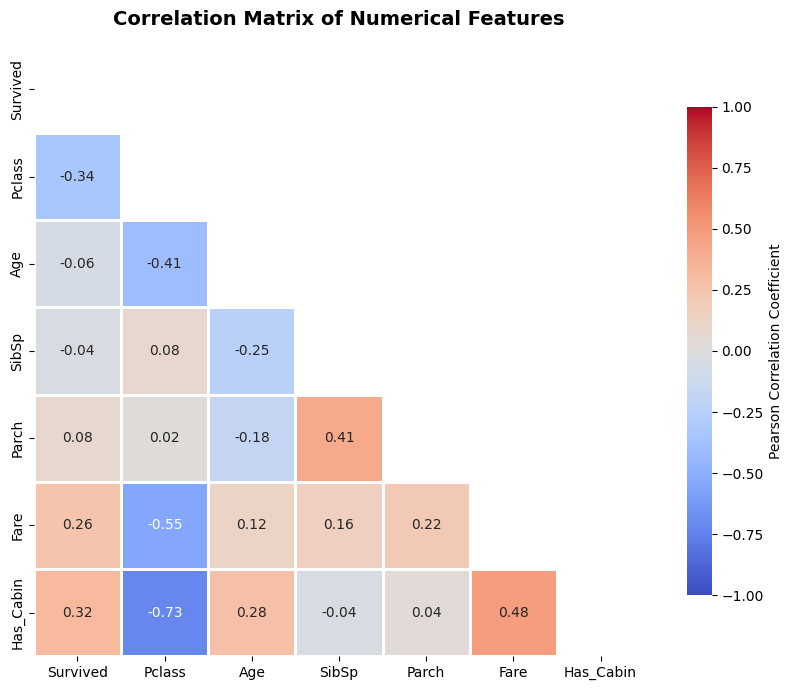

In [40]:
# 1. Select numerical features excluding arbitrary identifier
numerical_cols = [
    col
    for col in df_clean.select_dtypes(include=[np.number]).columns
    if col != "PassengerId"
]

# Calculate Pearson correlation matrix
correlation_matrix = df_clean[numerical_cols].corr()

print("--- Correlation Matrix ---")
display(correlation_matrix.round(3))

# 2. Visualize with Upper-Triangle Masked Heatmap
fig, ax = plt.subplots(figsize=(9, 7))

# Create boolean mask for the upper triangle
upper_mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))

# Draw correlation heatmap
sns.heatmap(
    correlation_matrix,
    mask=upper_mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.8,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation Coefficient"},
    ax=ax,
)

ax.set_title(
    "Correlation Matrix of Numerical Features",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

plt.tight_layout()
plt.show()

## 7. Key Findings & Conclusion

Based on our exploratory data analysis, we can summarize the answers to the core questions:

1. **Overall Survival Rate:**
   - Only **38.4%** of passengers survived the disaster, while **61.6%** perished, reflecting the severe shortage of lifeboats.

2. **Impact of Gender:**
   - Gender was the single most decisive factor: females had a **74.2%** survival rate, compared to just **18.9%** for males, confirming the strict enforcement of the "women and children first" protocol.

3. **Socioeconomic Status (Pclass & Fare):**
   - Evacuation priority heavily favored higher socioeconomic classes: **63.0%** of First Class passengers survived, versus **47.3%** in Second Class, and only **24.2%** in Third Class.
   - When looking at the interaction between gender and class, women in First Class had a **96.8%** survival rate, and women in Third Class (**50.0%**) still survived at higher rates than men in First Class (**36.9%**).
   - Higher fares directly correlated with higher survival probabilities, reflecting cabin location closer to the boat deck.

4. **Age Demographics:**
   - Children (aged 0–12) experienced the highest survival rate among age groups at **58.0%**.
   - Elderly passengers (aged 60+) had the lowest survival rate at **22.7%**.